# 02 - Pore segmentation and grain separation (Challenge task 2: "Porous Segmentation")

Notebook 01 gave a **phase map** (grain / pore / cement). A phase map says *which* pixels are pore, but not *how many
pores* there are or how big each one is. Here we split each phase into **individual objects**:

- **Pores**: the connected blue-epoxy network is split into **pore bodies**. The split lines are the **pore throats**
  (narrow constrictions). This is the coloured figure on p.5 of the exercise.
- **Grains**: grains that touch in 2D are separated. The class notebook used `ndi.label`, which keeps touching grains merged.

### Method: marker-controlled watershed on the distance transform
1. **Euclidean distance transform (EDT)** of the mask: the distance from each pixel to the nearest boundary. Pore bodies
   and grain centres are *maxima*, and throats and grain contacts are *saddles*.
2. Gaussian smoothing of the EDT (sigma = 1 px) and **h-maxima** (h = 0.5 px) as markers, one per candidate body.
3. **Watershed** of -EDT from the markers, restricted to the mask.
4. **Neck-ratio merge**: two neighbours are merged back when neck / min(inscribed radii) >= 0.7. A real contact or throat is
   narrow compared with the bodies it joins, while a waist inside one elongated grain is wide. This makes the criterion
   **scale-invariant**; a fixed h over- or under-splits depending on object size.

This is the principle of the **SNOW algorithm** (Sub-Network of the Oversegmented Watershed; Gostick, 2017,
*Phys. Rev. E* 96, 023307). We use `porespy.filters.snow_partitioning` as an independent cross-check.

**Structure of this notebook**
1. Split pores and grains into objects: how the split works (figure), then run it on both images.
2. Pore bodies (Challenge 2): the result for pores.
3. Separated grains (Task 3): the result for grains.
4. Checking the split: before/after the merge, zoomed checks, and the choice of the two parameters (h, neck ratio).
5. Cross-check of the pore split with PoreSpy SNOW.
6. Save the objects for notebooks 03-05.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import figstyle; figstyle.install()   # larger text in all figures
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import color, segmentation as sg
import porespy as ps
from segmentation import load_rgb, GRAIN, PORE
from objects import split_objects, object_table

plt.rcParams['figure.dpi'] = 90
IMAGES = {'small': '../Lamina_alunos2.png', 'large': '../Lamina_alunos_grande.png'}
imgs = {k: load_rgb(p) for k, p in IMAGES.items()}
phases = {k: np.load(f'../outputs/phases_{k}.npy') for k in IMAGES}

## 1. Split pores and grains into objects

**Why.** The phase map of notebook 01 says *which* pixels are grain or pore, not *where one grain ends and the next
begins*. Touching grains form one continuous area, and the pores form a connected network. To count objects and
measure each one (notebook 03), every grain and every pore body must get its own number.

**Why we calculate it and why it is important.** In one sentence: this section **cuts the grain and pore areas into individual grains and pore bodies**. It is useful for these reasons:

1. **It is needed for Task 3 and Challenge 2**: grain segmentation and pore segmentation mean identifying each grain and each pore separately.
2. **It makes per-object measurements possible**: size, shape and number of grains and pores (notebooks 03 and 05) need each object to be separate.
3. **It fixes the weakness of the class method**, which counted touching grains as one and the pore network as a few large blobs.

| What this section gives | Why it is useful |
|---|---|
| each grain and pore body with its own number | Task 3 and Challenge 2 |
| counts before and after the split | how much the class method under-counts |
| the labels dictionary | the input of notebooks 03-05 |

**What.** For each image and each phase (grain, pore), cut the phase area into individual objects.

**How.** The figure below explains the method step by step on real crops; the code cell after it runs the method on
both images and compares the number of objects before and after the split.

### The split, step by step

![Split steps](../outputs/figures/split_steps.png)

*Figure generated by `scripts/split_diagram.py` (small image; for each phase the crop is where the most cuts are
kept and undone). It uses the same `split_objects()` function as this notebook.*

- **(1) Connected components:** each connected blob gets one number, so touching grains, or pores joined by throats,
  count as **one** object.
- **(2) Distance to the edge:** every pixel gets its distance to the nearest boundary. Object centres are bright
  peaks; the contact between two objects is a dark, narrow neck. Each peak becomes a **marker** (cyan) = one candidate
  object.
- **(3) Watershed:** starting from each marker, regions grow outwards until they meet. The **cuts** (white) form at the
  necks: grain contacts for grains, pore throats for pores.
- **(4) Neck-ratio merge:** the watershed sometimes cuts one object at a "waist". For every cut the code compares the
  width of the neck with the width of the smaller piece. **Narrow neck (ratio < 0.7) = two real objects -> the cut is
  kept (red)**. **Wide neck (ratio >= 0.7) = a waist inside one object -> the cut is undone and the pieces merged
  (yellow)**. The schematic on the right shows both cases.

The table below compares the counts: **connected components** (step 1) against **objects after watershed + merge**
(step 4).

### Run the split on both images

**How.** For each image and phase: take the pixels of that phase (`phases[k] == code_`), run `split_objects()` (in
`src/objects.py`) and store the result. The table compares the number of **connected components** (touching objects
counted as one, step 1 of the figure) with the number of **objects after watershed + merge** (step 4).

In [2]:
labels = {}
rows = []
for k in IMAGES:
    for name, code_ in [('grain', GRAIN), ('pore', PORE)]:
        m = phases[k] == code_
        L = split_objects(m)
        labels[(k, name)] = L
        rows.append({'image': k, 'phase': name,
                     'connected components (ndi.label)': ndi.label(m)[1],
                     'objects after watershed + merge': int(L.max())})
counts = pd.DataFrame(rows).set_index(['image', 'phase'])
counts

connected components (ndi.label)  objects after watershed + merge
image phase                                                                   
small grain                               480                              803
      pore                                282                              406
large grain                              2066                             3739
      pore                               1199                             1751

With plain connected-component labelling, the pore network appears as a few large clusters and touching grains stay
merged. The watershed step separates pore bodies at their throats and splits touching grains.

**What the split gives us: the `labels` dictionary.** The cell above stores its result in a Python dictionary
called `labels`, with one entry per image and phase:

| Key | Value |
|---|---|
| `('small', 'grain')` | label image of the small image's grains (803 objects) |
| `('small', 'pore')` | label image of the small image's pores (406 objects) |
| `('large', 'grain')` | label image of the large image's grains (3,739 objects) |
| `('large', 'pore')` | label image of the large image's pores (1,751 objects) |

Each **label image** is an array the same size as the photo, where every pixel holds a number: `0` if it is not part
of that phase, or `1, 2, 3, ...` for the object it belongs to (all pixels of pore body #57 hold 57). The number of
objects is the largest value in the array.

**Sections 2 and 3 only plot this dictionary.** They do not compute anything new:
- **Section 2** takes the pore entries and paints each pore body in its own random colour (background white), next to
  the original photo.
- **Section 3** takes the grain entries and paints each grain in its own random colour (background black), and draws
  a red outline around every grain on the original photo to check the split by eye.

The colours have no meaning; they only make neighbouring objects easy to tell apart.

## 2. Pore bodies

**Why.** This is Challenge 2 (porous segmentation): each pore body as a separate object, like the coloured figure on
page 5 of the exercise.

**Why we calculate it and why it is important.** In one sentence: this section **shows the result of the pore segmentation**: Challenge 2. It is useful for these reasons:

1. **It answers Challenge 2** (porous segmentation), reproducing the coloured pore figure of page 5 of the exercise.
2. **Pore bodies are the storage units of a reservoir**; their number and size describe the pore system.
3. **The cuts between them are the pore throats**, which control flow (measured in notebook 03).

| What this section gives | Why it is useful |
|---|---|
| each pore body in its own colour | Challenge 2 |
| number of pore bodies | description of the pore system |
| where the network was cut | the pore throats |

**What.** For each image: the original photo (left) and the pore bodies (right), each in its own random colour on a
white background. Grains and cement are white.

**How.** The label images of section 1 are turned into colours with `random_label_rgb()`: one random colour per
object number. The colours carry no meaning; they only make neighbouring pores easy to tell apart.

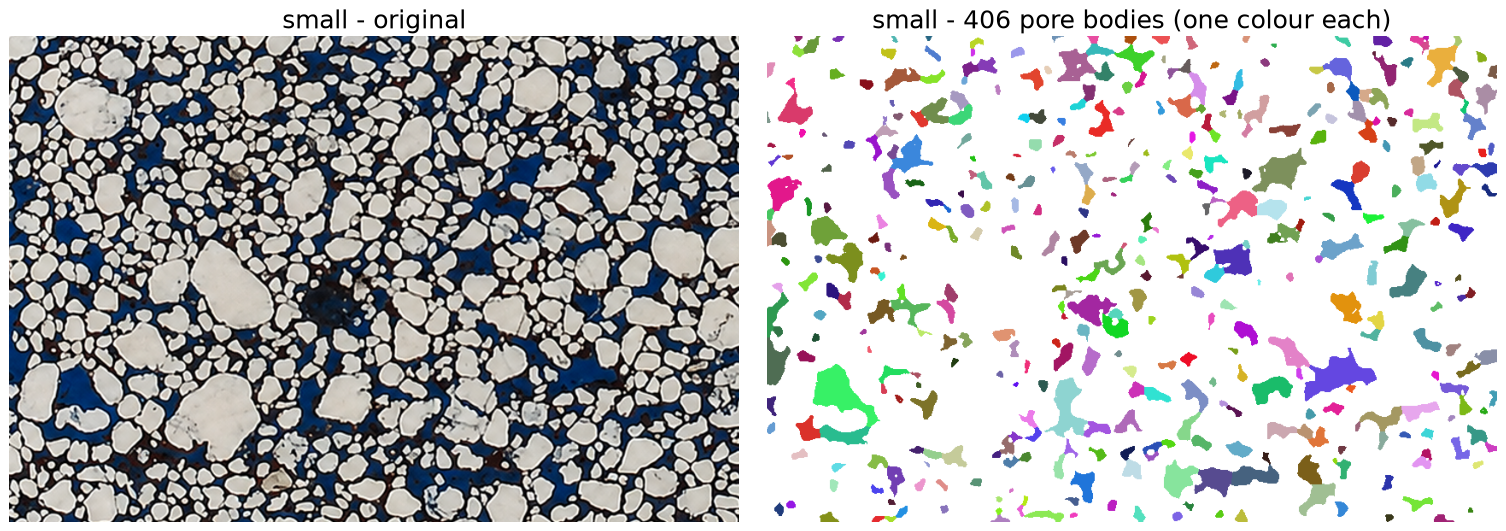

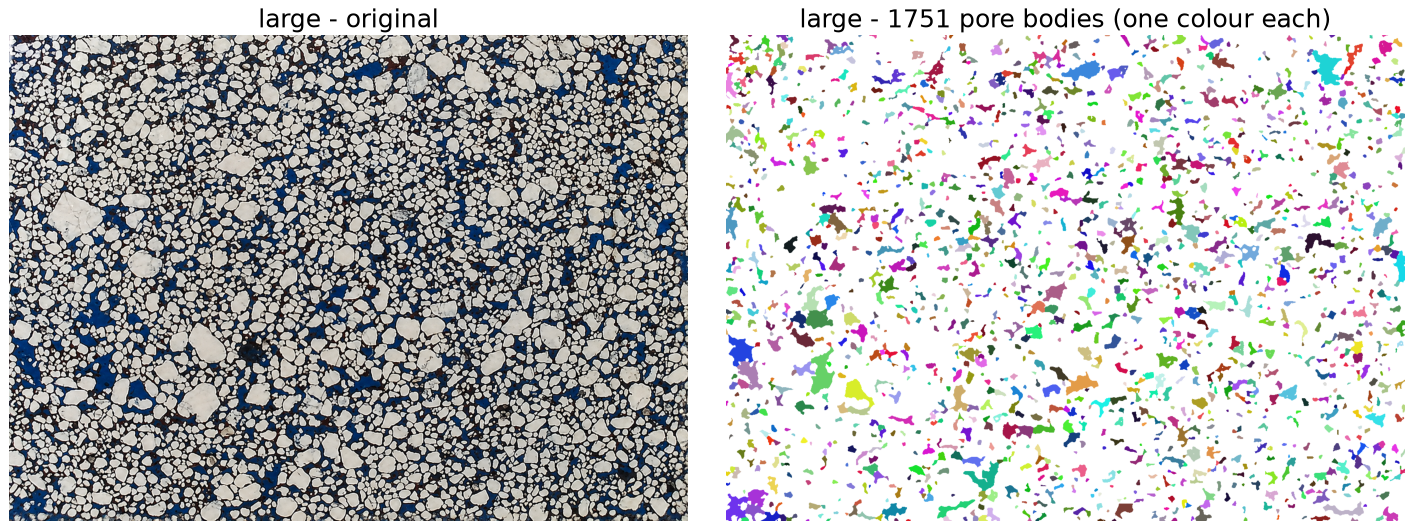

In [3]:
def random_label_rgb(L, seed=3, bg=(1, 1, 1)):
    rng = np.random.default_rng(seed)
    lut = rng.uniform(0.05, 0.95, (L.max() + 1, 3)); lut[0] = bg
    return lut[L]

for k in IMAGES:
    fig, ax = plt.subplots(1, 2, figsize=(17, 6))
    ax[0].imshow(imgs[k]); ax[0].set_title(f'{k} - original')
    ax[1].imshow(random_label_rgb(labels[(k, 'pore')]))
    ax[1].set_title(f'{k} - {labels[(k, "pore")].max()} pore bodies (one colour each)')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

**Reading the result.** 406 pore bodies in the small image and 1,751 in the large one. Where two colours touch, the
connected pore network was cut at a narrow throat. Isolated small pores have a single colour.

## 3. Separated grains

**Why.** This is Task 3 (grain segmentation): each grain as a separate object, including grains that touch.

**Why we calculate it and why it is important.** In one sentence: this section **shows the result of the grain segmentation**: Task 3. It is useful for these reasons:

1. **It answers Task 3** (grain segmentation).
2. **Individual grains are needed for grain size and sorting** (notebook 03) and grain shape (notebook 05), classic descriptors of a sedimentary rock.
3. **The outlines on the photo allow a visual check** that the split follows the real grain edges.

| What this section gives | Why it is useful |
|---|---|
| each grain in its own colour | Task 3 |
| red outlines on the photo | visual check of the split |
| number of grains | input for size and shape statistics |

**What.** For each image: the grains in random colours on a black background (left) and the original photo with a
red outline around every grain (right).

**How.** Same colouring as section 2. The outlines are drawn with `mark_boundaries()` wherever the grain number
changes, so they also appear **between** touching grains.

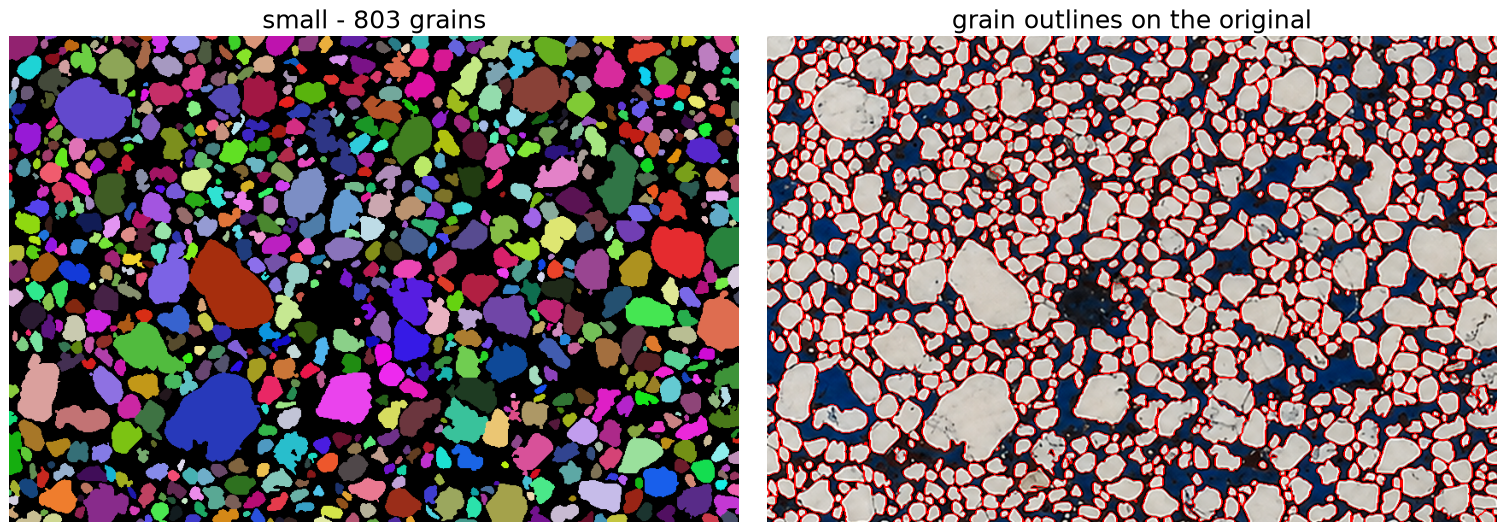

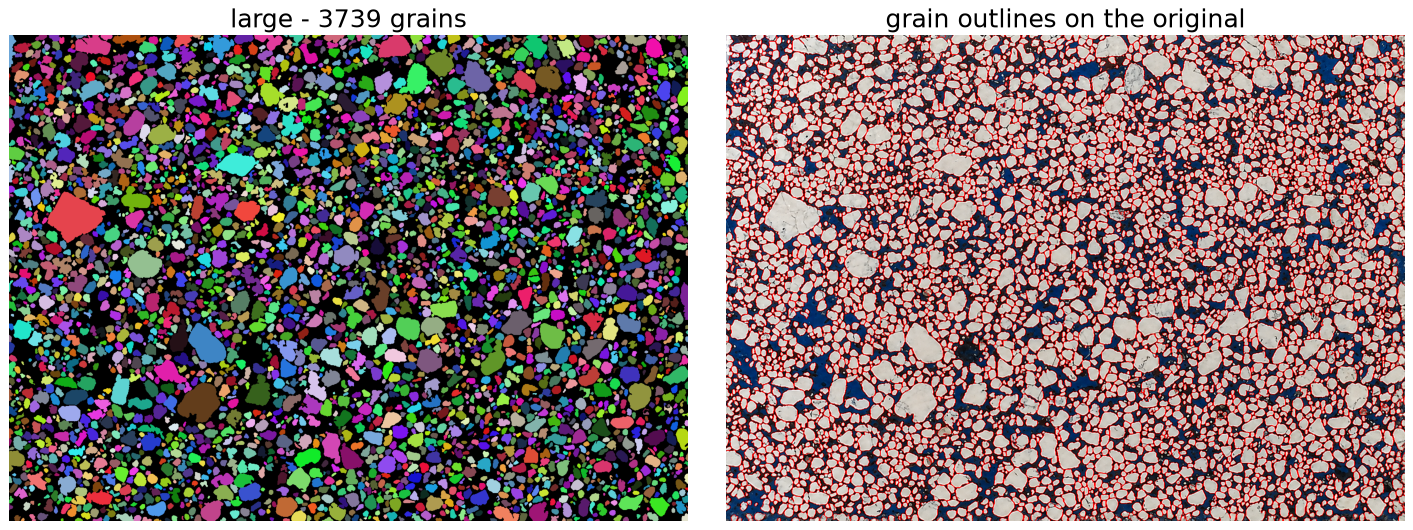

In [4]:
for k in IMAGES:
    fig, ax = plt.subplots(1, 2, figsize=(17, 6))
    ax[0].imshow(random_label_rgb(labels[(k, 'grain')], bg=(0, 0, 0)))
    ax[0].set_title(f'{k} - {labels[(k, "grain")].max()} grains')
    ax[1].imshow(sg.mark_boundaries(imgs[k], labels[(k, 'grain')], color=(1, 0, 0)))
    ax[1].set_title('grain outlines on the original')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

**Reading the result.** 803 grains in the small image and 3,739 in the large one. The red outlines follow the visible
grain edges, and touching grains have a red line between them. Whether every cut is right is checked in section 4.

## 4. Checking the split

**Why.** The split makes two kinds of decision: where to cut (watershed) and which cuts to undo (neck-ratio merge).
Both can go wrong: touching grains left joined, or one grain cut in two. This section checks the decisions visually
and shows how the two parameters were chosen.

**Why we calculate it and why it is important.** In one sentence: this section **checks that the split makes the right decisions** and explains how its two settings were chosen. It is useful for these reasons:

1. **Errors in the split affect every later result**: two grains counted as one look like one big irregular grain; one grain cut in two looks like two small ones.
2. **It checks the three cases that matter**: touching grains separated, large grains kept whole, pores cut at their throats.
3. **It justifies the two settings** (h and neck ratio) and shows how much the results depend on them.

| What this section gives | Why it is useful |
|---|---|
| before / after the merge | what the merge changes |
| zoomed checks | the split is right in the difficult cases |
| choice of h and neck ratio | how the settings were chosen and how sensitive they are |

**What.** Three checks, from the whole image down to single grains:
1. the whole image before and after the merge;
2. zoomed checks of the three situations the split must get right;
3. the two parameters (h and neck ratio): what they mean and how the number of objects depends on them.

### Checking the watershed + merge: before and after, whole image

The next two figures check that the split (watershed + neck-ratio merge, explained at the top of this notebook)
works correctly. First the whole small image, **before** and **after** the merge:

![Merge overview](../outputs/figures/merge_overview.png)

*Figure generated by `scripts/split_check_diagram.py`.*

- **Left, before the merge (watershed only):** 854 grains and 462 pores. White lines are the cuts between pieces.
  **Yellow lines are the cuts the merge will undo**, because the neck there is wide (a waist inside one object).
- **Right, after the merge:** 803 grains and 406 pores. The yellow cuts are gone: 51 grain pieces and 56 pore pieces
  were joined back to their neighbour (joined pieces now share one colour). The remaining white lines are real grain
  contacts and pore throats.
- **Red boxes 1, 2, 3** are the areas zoomed in below.

### Zoomed quality check (small image)

The whole image is too small to judge single grains, so we zoom in on **boxes 1, 2 and 3** of the figure above:
the three situations the watershed + merge must get right. Each row states what **should** happen. The circle
marks where to look (red on the photo, yellow on the result). The spots are found automatically from the split
itself.

![Split check](../outputs/figures/split_check.png)

*Figure generated by `scripts/split_check_diagram.py` (same `split_objects()` as this notebook).*

- **Row 1, touching grains must be separated.** Two grains touch inside the circle. In the result each has its own
  colour, with a white line between them: the split found the contact.
- **Row 2, a large elongated grain must NOT be cut.** The watershed alone (centre) cuts this grain in two at its
  "waist". The neck there is wide compared with the grain, so the neck-ratio merge joins the two pieces back into
  one grain (right).
- **Row 3, pores must be split at their throats.** The blue pore network narrows inside the circle. The split cuts
  it there, so each side becomes a separate pore body (two colours).

### Choice of the parameters h and neck ratio

**Parameter choice: h and the neck ratio.** The split has two settings. Both work on the *distance to the edge*
along a path from one piece's centre, through the contact, to the other piece's centre: two hills (the pieces)
with a dip between them (the contact).

- **h** (step 2, markers): a hill gets its own marker only if it rises at least h pixels above the dip. We use a
  low **h = 0.5 px**, so the watershed cuts wherever there *might* be a contact.
- **Neck ratio** (step 4, merge) = dip height / height of the smaller hill = contact width / grain width. **Below
  0.7** the contact is much thinner than the grains, so they are two grains and the cut is kept. **0.7 or more** means
  the grain barely narrows (a waist), so the cut is undone. Being a ratio, it treats small and large grains the same;
  a fixed h cannot do that.

![h and neck ratio](../outputs/figures/h_neck_ratio.png)

*Figure generated by `scripts/h_neck_diagram.py`. Rows 1-2: two real cases; the dip in each profile is the neck
value used by the code (case 1: ratio 0.19, kept; case 2 = box 2 above: ratio 0.93, undone). Row 3: number of grains
for other values of h (no merge) and of the neck ratio (h = 0.5).*

The table below gives the object counts for combinations of the two parameters; the values used are h = 0.5 and
neck ratio = 0.7.

In [5]:
m_g, m_p = phases['small'] == GRAIN, phases['small'] == PORE
rows = []
for h in [0.5, 1.0, 2.0]:
    for r in [None, 0.5, 0.6, 0.7, 0.8]:
        rows.append({'h': h, 'neck_ratio': 'none' if r is None else r,
                     'n grains': split_objects(m_g, h=h, neck_ratio=r).max(),
                     'n pores': split_objects(m_p, h=h, neck_ratio=r).max()})
sens = pd.DataFrame(rows).set_index(['h', 'neck_ratio'])
sens

n grains  n pores
h   neck_ratio                   
0.5 none             854      462
    0.5              739      340
    0.6              777      375
    0.7              803      406
    0.8              830      447
1.0 none             806      404
    0.5              737      336
    0.6              771      367
    0.7              789      388
    0.8              804      404
2.0 none             729      343
    0.5              704      323
    0.6              721      336
    0.7              729      340
    0.8              729      343

**Reading the table.** Each row is one run of the split on the small image. Without the merge ("none"), raising h
from 0.5 to 2 lowers the grain count from 854 to 729, because fewer markers means fewer cuts. With h = 0.5, the neck
ratio controls how many cuts are undone: 739 grains at 0.5, **803 at 0.7 (used)**, 830 at 0.8. The pore counts follow
the same pattern. The counts vary by about +-4 % around the chosen values; the choice itself comes from the visual
checks above.

## 5. Cross-check with PoreSpy SNOW (Gostick 2017)

**Why.** Our pore split is home-made. Comparing it with a published, independent method shows whether the result is
reasonable.

**Why we calculate it and why it is important.** In one sentence: this section **compares our pore split with an independent, published method**. It is useful for these reasons:

1. **Our method is home-made**; agreement with a widely used method (SNOW, Gostick 2017) shows it is reasonable.
2. **It shows what depends on the method**: the number of pore bodies varies with the method, the pore area does not.
3. **It supports the reported results** with an external reference.

| What this section gives | Why it is useful |
|---|---|
| pore bodies from both methods | independent validation |
| size distributions compared | agreement of the results |
| difference in counts | which results depend on the method |

**What.** PoreSpy's **SNOW** algorithm (Gostick, 2017) is widely used to split pore space into pore bodies; it is
based on the same idea (watershed on the distance map). Top: the pore bodies of both methods side by side. Bottom:
their size distributions.

**How.** `porespy.filters.snow_partitioning()` on the same pore mask, with its default settings.

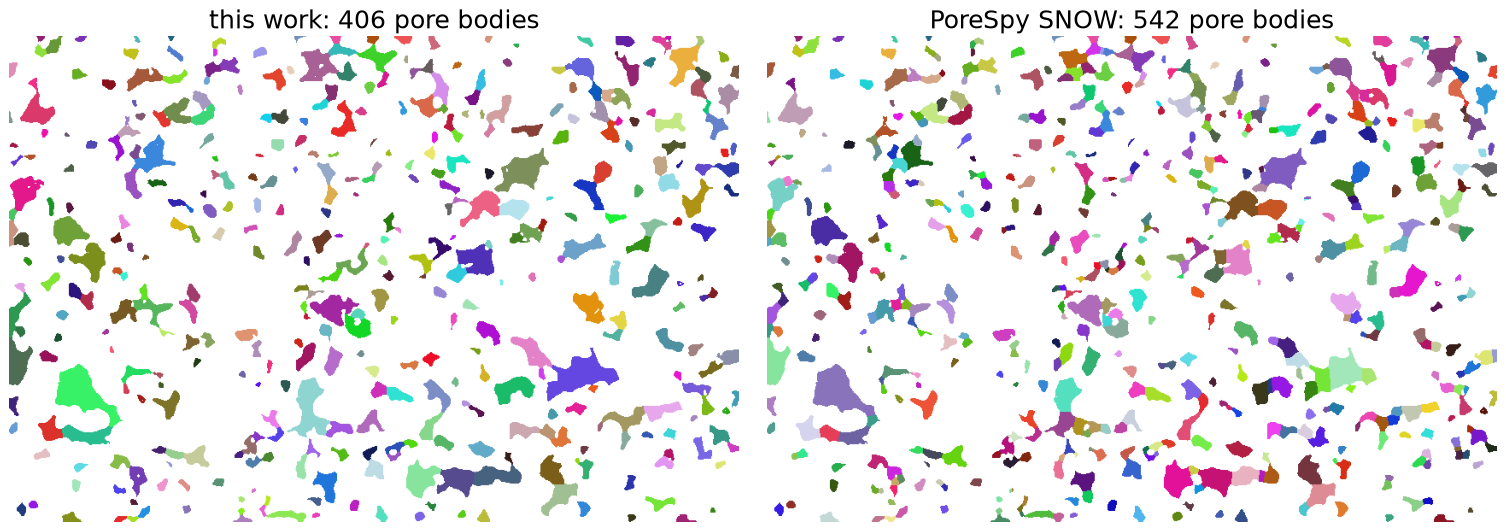

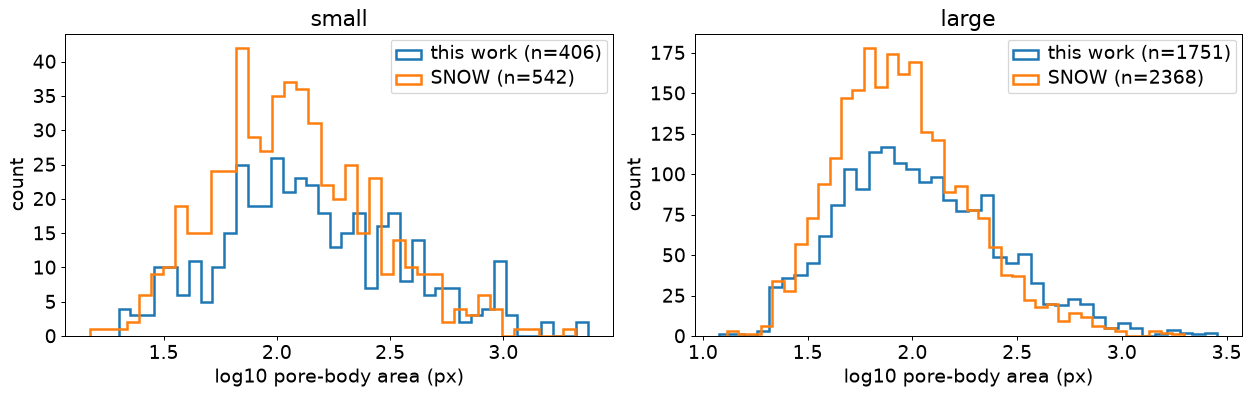

In [6]:
snow = {}
for k in IMAGES:
    m = phases[k] == PORE
    reg = ps.filters.snow_partitioning(m, r_max=4, sigma=0.4).regions * m
    snow[k] = sg.relabel_sequential(reg)[0]

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ax[0].imshow(random_label_rgb(labels[('small', 'pore')])); ax[0].set_title(f'this work: {labels[("small", "pore")].max()} pore bodies')
ax[1].imshow(random_label_rgb(snow['small'])); ax[1].set_title(f'PoreSpy SNOW: {snow["small"].max()} pore bodies')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, k in zip(ax, IMAGES):
    for nm, L in [('this work', labels[(k, 'pore')]), ('SNOW', snow[k])]:
        area = np.bincount(L.ravel())[1:]
        a.hist(np.log10(area[area > 0]), bins=40, histtype='step', lw=2, label=f'{nm} (n={L.max()})')
    a.set_xlabel('log10 pore-body area (px)'); a.set_ylabel('count'); a.set_title(k); a.legend()
plt.tight_layout(); plt.show()

**Reading the result.** SNOW splits a little more finely (542 pore bodies vs 406 in the small image), so it has more,
smaller bodies. The two size distributions largely overlap. The number of pore bodies depends on how a throat is
defined, so it must be reported with the method and its parameters. The pore **area** (porosity) is not affected.

## 6. Save label images and per-object tables (used by notebooks 03-05)

**What is saved** (in `outputs/`):
- `labels_grain_small.npy`, `labels_pore_small.npy`, `labels_grain_large.npy`, `labels_pore_large.npy`: the four label
  images of the `labels` dictionary (0 = background, 1, 2, 3... = object number), used by notebooks 03-05;
- `02_objects.csv`: one row per object with its area, perimeter, diameter, axes, orientation and shape;
- `02_object_counts.csv`: the table of section 1;
- `02_split_sensitivity.csv`: the parameter table of section 4.

The table shown below summarises the objects per image and phase: number of objects, how many touch the image
border, and the median area in pixels.

In [7]:
tables = []
for (k, name), L in labels.items():
    np.save(f'../outputs/labels_{name}_{k}.npy', L)
    t = object_table(L, name); t.insert(0, 'image', k)
    tables.append(t)
objs = pd.concat(tables, ignore_index=True)
objs.to_csv('../outputs/02_objects.csv', index=False)
counts.to_csv('../outputs/02_object_counts.csv')
sens.to_csv('../outputs/02_split_sensitivity.csv')
objs.groupby(['image', 'phase']).agg(n=('label', 'size'), on_border=('on_border', 'sum'),
                                     median_area_px=('area', 'median')).round(1)

n  on_border  median_area_px
image phase                                 
large grain  3739        174           148.0
      pore   1751         75            99.0
small grain   803         93           194.0
      pore    406         40           129.5

## Findings

- Connected-component labelling (the class approach) **under-counts**: the pore space forms a few interconnected clusters,
  and touching grains are counted as one.
- The distance-transform watershed with a **scale-invariant neck-ratio merge** separates pore bodies at their throats and
  splits touching grains. Large single grains stay whole.
- The pore partition agrees well with **PoreSpy SNOW**. SNOW splits a little more finely, so it gives more, smaller bodies.
  The size distributions overlap. Pore-body counts depend on the definition of a throat, so they should be reported with
  their parameters. Pore *area fraction* does not depend on this choice.
- Objects touching the image border are flagged (`on_border`). They are kept for area fractions and excluded from
  size and shape statistics (notebooks 03 and 05), because their true size is unknown.